# Overfitting and Ensemble Trees: Random Forests and Gradient Boosting

In this notebook, we will study overfitting and two ensemble methods that reduce it, using the telecom customer churn dataset from last class. We first detect overfitting in a single decision tree by comparing its performance on training data and test data. We then train a Random Forest and an XGBoost model and compare them with the decision trees from Week 9.
____
We'll cover:
1. Loading and inspecting the dataset.
2. Preprocessing: Encoding categorical data.
3. Splitting the data into training and testing sets.
4. Detecting overfitting by comparing training and test scores.
5. Plotting an overfitting curve across tree depths.
6. Training a Random Forest model.
7. Measuring feature importance with the Random Forest.
8. Training an XGBoost model with early stopping.

*Appendix (if time allows): Choosing a decision threshold with Youden's J.*

## **Step 1: Load and Inspect the Data**

We use the same telecom customer churn dataset as last class. It is available from OpenML and includes details about 5,000 phone-plan customers and whether they left the company (churned).

In [22]:
# Importing necessary libraries
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import fetch_openml

# Fetch dataset
data = fetch_openml(data_id=40701, as_frame=True).frame

### **Step 2: Data Preprocessing**

Our next step is to prepare the data for modeling:

- **Encoding Categorical Variables:**
   Decision tree algorithms can handle numerical inputs, so we convert
   categorical variables (e.g., `international_plan`) into numeric format using one-hot encoding.

*Note: We use drop_first=True to avoid the dummy variable trap.*

In [23]:
# Encoding categorical variables
df = pd.get_dummies(data, columns=['international_plan', 'voice_mail_plan'], drop_first=True) # Use drop_first = True to avoid "dummy trap"
df['number_customer_service_calls'] = df['number_customer_service_calls'].astype(int) # Stored as text; convert to numbers

# Define features and target
features = ['account_length', 'number_vmail_messages',
            'total_day_minutes', 'total_day_calls', 'total_day_charge',
            'total_eve_minutes', 'total_eve_calls', 'total_eve_charge',
            'total_night_minutes', 'total_night_calls', 'total_night_charge',
            'total_intl_minutes', 'total_intl_calls', 'total_intl_charge',
            'number_customer_service_calls', 'international_plan_1', 'voice_mail_plan_1']
X = df[features]
y = df["class"].astype(int)

# Preview the cleaned dataset
print(X.head())
print(y.head())

   account_length  number_vmail_messages  total_day_minutes  total_day_calls  \
0             128                     25              265.1              110   
1             107                     26              161.6              123   
2             137                      0              243.4              114   
3              84                      0              299.4               71   
4              75                      0              166.7              113   

   total_day_charge  total_eve_minutes  total_eve_calls  total_eve_charge  \
0             45.07              197.4               99             16.78   
1             27.47              195.5              103             16.62   
2             41.38              121.2              110             10.30   
3             50.90               61.9               88              5.26   
4             28.34              148.3              122             12.61   

   total_night_minutes  total_night_calls  total_night_c

### **Step 3: Splitting the Data**

We split the dataset into training and testing sets. The training set is used to build our models, while the testing set is used to evaluate their performance. We use the same split as last class (`random_state=42`) so that the results are comparable.

In [24]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing subsets
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42)

### **Step 4: Detecting Overfitting with Training and Test Scores**

A model **overfits** when it memorizes the training data, including its noise, instead of learning patterns that generalize to new data. We detect overfitting by comparing two scores:

- **Training Score:** Performance on the data the model was trained on.
- **Test Score:** Performance on data the model has not seen.
- **Gap:** The training score minus the test score. A large gap is the main sign of overfitting.

We define a helper function that reports both scores so that every model is evaluated the same way. Because only about 14% of customers churn, we use the **F1 score for the churn class** rather than accuracy, as we did with GridSearchCV last class.

Here, we start with a decision tree with default parameters, which keeps splitting until every leaf is pure.

In [25]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score

# Helper function: compare a model's F1 score on training data vs. test data
def train_test_scores(model, name):
    train_f1 = f1_score(y_train, model.predict(X_train))
    test_f1 = f1_score(y_test, model.predict(X_test))
    print(f"{name}: Train F1 = {train_f1:.2f} | Test F1 = {test_f1:.2f} | Gap = {train_f1 - test_f1:.2f}")

# Initialize and train a decision tree with default parameters (no limit on growth)
tree_model = DecisionTreeClassifier(random_state = 42)
tree_model.fit(X_train, y_train)

# Compare training and test scores
train_test_scores(tree_model, "Default Decision Tree")

Default Decision Tree: Train F1 = 1.00 | Test F1 = 0.74 | Gap = 0.26


### **Step 5: The Overfitting Curve**

To see how model complexity affects overfitting, we train decision trees with `max_depth` from 1 to 20 and record two scores for each tree:

- **Training F1:** How well the tree fits the data it was trained on.
- **Cross-Validation F1:** The average F1 across 5 folds of the training data. This estimates performance on new data without using the test set.

The plot shows three regions:
- **Underfitting (shallow trees):** Both scores are low because the tree is too simple to capture the patterns in the data.
- **Best Fit (moderate depth):** Cross-validation F1 reaches its highest value.
- **Overfitting (deep trees):** Training F1 approaches 1.00 while cross-validation F1 declines.

*Note: This loop is a manual version of the search that GridSearchCV performed last class.*

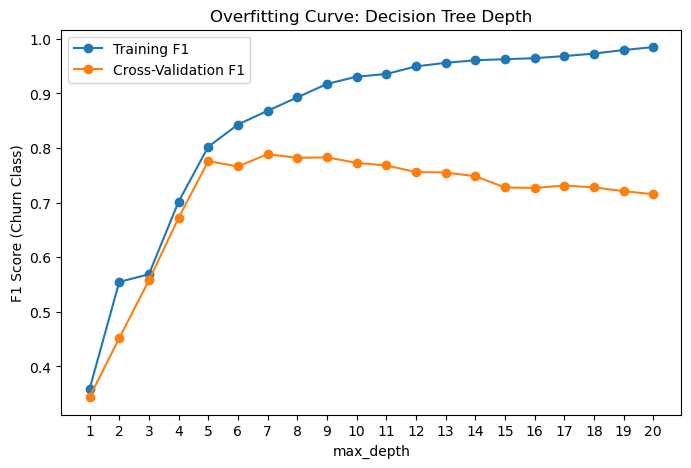

Best depth by cross-validation: 7 (CV F1 = 0.79)


In [26]:
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score

# Define a range of tree depths to explore
depths = range(1, 21)
train_scores = []
cv_scores = []

# Loop through each depth
for depth in depths:
    # Initialize a decision tree with this max_depth
    tree_temp = DecisionTreeClassifier(max_depth = depth, random_state = 42)
    # Score on the training data the tree learned from
    tree_temp.fit(X_train, y_train)
    train_scores.append(f1_score(y_train, tree_temp.predict(X_train)))
    # Score with 5-fold cross-validation (an estimate of performance on new data)
    cv_scores.append(cross_val_score(tree_temp, X_train, y_train,
                                     cv = 5,
                                     scoring = 'f1').mean())

# Plot both scores against tree depth
plt.figure(figsize=(8, 5))
plt.plot(depths, train_scores, marker='o', label='Training F1')
plt.plot(depths, cv_scores, marker='o', label='Cross-Validation F1')
plt.title('Overfitting Curve: Decision Tree Depth')
plt.xlabel('max_depth')
plt.ylabel('F1 Score (Churn Class)')
plt.xticks(depths)
plt.legend()
plt.show()

best_depth = depths[np.argmax(cv_scores)]
print(f"Best depth by cross-validation: {best_depth} (CV F1 = {max(cv_scores):.2f})")

### **Step 6: Train a Random Forest Model**

In Week 9, we trained a Random Forest without examining how it works. A Random Forest is an **ensemble** method: it combines the predictions of many decision trees to reduce overfitting. It has three key components:

- **Bootstrap Samples:** Each tree is trained on a bootstrap sample, a random sample of the training rows drawn with replacement.
- **Random Feature Subsets:** At each split, a tree considers only a random subset of the features, so the trees differ from one another.
- **Voting:** The forest combines the votes of all its trees (100 by default). Because the trees make different mistakes, many of those mistakes cancel out.

Training many trees on bootstrap samples and combining their votes is called **bagging** (**b**ootstrap **agg**regat**ing**). Unlike a deeper tree, a larger forest does not overfit: adding trees only increases training time.

*Note: A Random Forest often scores close to 1.00 on the training data because each tree memorizes its own bootstrap sample. The test score shows whether this memorization hurts performance on new data.*

In [27]:
# Import and fit RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier

# Initialize and train a random forest (100 trees by default)
rf_model = RandomForestClassifier(random_state = 42)
rf_model.fit(X_train, y_train)

# Compare training and test scores
train_test_scores(rf_model, "Random Forest")

Random Forest: Train F1 = 1.00 | Test F1 = 0.84 | Gap = 0.16


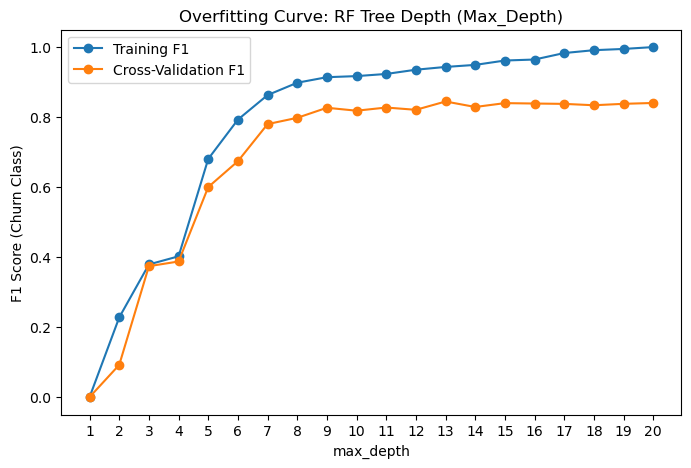

Best depth by cross-validation: 13 (CV F1 = 0.84)


In [29]:
# Define a range of tree depths to explore
depths = range(1, 21)
train_scores = []
cv_scores = []

# Loop through each depth
for depth in depths:
    rf_temp = RandomForestClassifier(max_depth = depth, random_state = 42)

    # Score on the training data the tree learned from
    rf_temp.fit(X_train, y_train)
    train_scores.append(f1_score(y_train, rf_temp.predict(X_train)))

    # Score with 5-fold cross-validation (an estimate of performance on new data)
    cv_scores.append(cross_val_score(rf_temp, X_train, y_train, cv = 5, scoring = 'f1').mean())

# Plot both scores against tree depth
plt.figure(figsize=(8, 5))
plt.plot(depths, train_scores, marker='o', label='Training F1')
plt.plot(depths, cv_scores, marker='o', label='Cross-Validation F1')
plt.title('Overfitting Curve: RF Tree Depth (Max_Depth)')
plt.xlabel('max_depth')
plt.ylabel('F1 Score (Churn Class)')
plt.xticks(depths)
plt.legend()
plt.show()

best_depth = depths[np.argmax(cv_scores)]
print(f"Best depth by cross-validation: {best_depth} (CV F1 = {max(cv_scores):.2f})")

### **Step 7: Feature Importance**

A Random Forest contains too many trees to visualize, but it can report which features it relied on most. **Feature importance** measures how much each feature improved the splits, averaged across all the trees in the forest.

When reading the chart, keep two cautions in mind:
- **Correlated Features:** `total_day_minutes` and `total_day_charge` carry the same information (charge = minutes × rate), so the forest divides the importance between them.
- **Importance Is Not Causation:** Feature importance shows which features the model uses, not which features cause churn.

In [30]:
rf_model.feature_importances_

array([0.02961325, 0.03080992, 0.14408957, 0.02865142, 0.13705098,
       0.06751397, 0.0264152 , 0.06719655, 0.04188023, 0.02583045,
       0.03900558, 0.03992528, 0.05029857, 0.04165642, 0.12520888,
       0.08215234, 0.0227014 ])

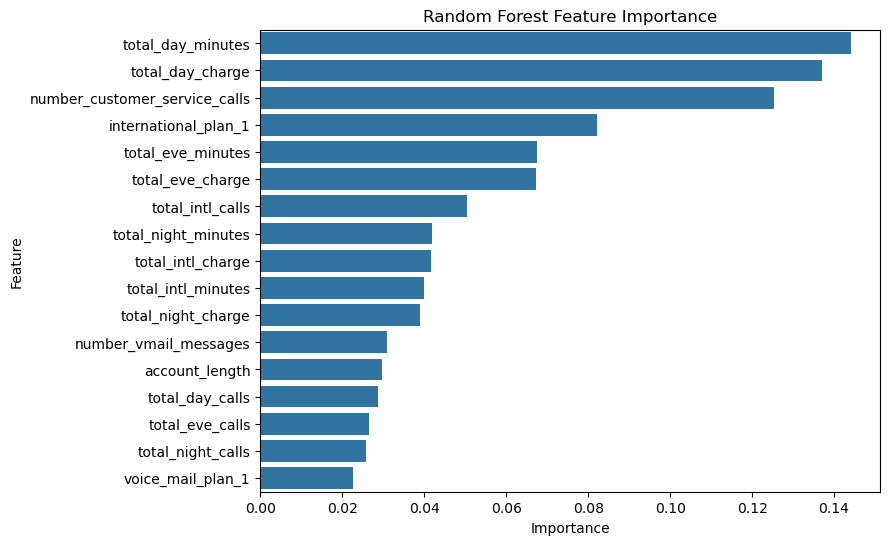

In [31]:
# Get feature importances from the random forest and sort them
importances = pd.Series(rf_model.feature_importances_, index = X_train.columns).sort_values(ascending = False)

# Plot feature importances
plt.figure(figsize=(8, 6))
sns.barplot(x = importances.values, y = importances.index)
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

<Axes: >

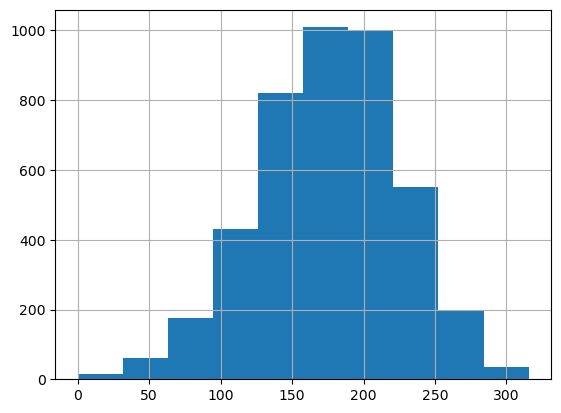

In [32]:
(df[df['class']=='0']['total_day_minutes']).hist()

<Axes: >

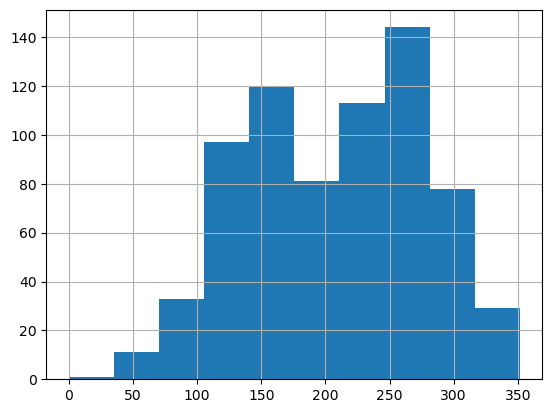

In [33]:
(df[df['class']=='1']['total_day_minutes']).hist()

### **Step 8: Gradient Boosting with XGBoost**

A Random Forest builds its trees **independently** and combines their votes. **Gradient boosting** builds trees **sequentially**: each new tree focuses on the errors made by the trees before it. XGBoost, which we used in Week 9, is a widely used implementation of gradient boosting.

Unlike a Random Forest, a boosting model can overfit if it trains for too many rounds, because later trees begin to fit noise in the training data. To decide when to stop without using the test set, we split off part of the training data as a **validation set**:

- **Training Set:** Used to fit the model.
- **Validation Set:** Used to evaluate the model after each boosting round.
- **Test Set:** Held back for the final comparison of all models.

We then use **early stopping**: training stops once the validation **log loss** has not improved for 20 consecutive rounds. Log loss measures how far the predicted probabilities are from the true labels; lower values are better.

In [35]:
from xgboost import XGBClassifier

# Split the training data again to create a validation set
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train,
                                            test_size=0.2,
                                            random_state=42)

# Train XGBoost with early stopping: stop if validation log loss doesn't improve for 20 rounds
# TO DO: Add parameters to XGBoostClassifier
xg_model = XGBClassifier(n_estimators = 300,
                         eval_metric = 'logloss',
                         early_stopping_rounds = 20)

xg_model.fit(X_tr, y_tr,
             eval_set = [(X_val, y_val)],
             verbose = False)


print(f"Best round: {xg_model.best_iteration + 1}")

# Compare training and test scores (training F1 here covers the full training set, including the validation rows)
train_test_scores(xg_model, "XGBoost (early stopping)")

Best round: 56
XGBoost (early stopping): Train F1 = 0.97 | Test F1 = 0.85 | Gap = 0.12


### **Step 8.1: Visualizing Log Loss by Boosting Round**

To see when XGBoost begins to overfit, we train a second XGBoost model for all 300 rounds without early stopping and record its **log loss** on the training set and the validation set after every round.

**Log loss** measures how closely a model's predicted probabilities match the true labels. For each customer, the model predicts a probability of churn, and log loss assigns a penalty based on how far that probability is from the actual outcome. For a customer who churned:

- **Confident and Correct:** A predicted churn probability of 0.90 receives a small penalty (about 0.11).
- **Uncertain:** A predicted churn probability of 0.50 receives a moderate penalty (about 0.69).
- **Confident and Wrong:** A predicted churn probability of 0.10 receives a large penalty (about 2.30).

The log loss for a dataset is the average penalty across all customers. A perfect model has a log loss of 0, so lower values are better. We track log loss instead of F1 because F1 changes only when a prediction crosses the 0.5 threshold, while log loss changes whenever a predicted probability changes. This makes it better suited to tracking progress from one round to the next.

The code uses the following:
- **`n_estimators = 300`:** Trains for all 300 rounds so that we can see the full curve.
- **`eval_set`:** Lists the datasets to evaluate after each round. XGBoost labels them by position: `validation_0` is the training set and `validation_1` is the validation set.
- **`evals_result()`:** Returns the log loss recorded for each dataset at every round.
- **`np.argmin(...) + 1`:** Finds the round with the lowest validation log loss. We add 1 because Python counts from 0, while boosting rounds count from 1.

The plot shows:
- **Training Log Loss:** Decreases steadily toward 0 as each new tree fits the training data more closely.
- **Validation Log Loss:** Decreases at first, reaches its lowest point at the dashed line, and then gradually rises.
- **Overfitting:** After the dashed line, additional trees improve the training score but worsen the validation score. This is the same pattern we saw in the overfitting curve in Step 5.

*Note: The dashed line marks the same round that early stopping reported as the best round in Step 8. Early stopping finds this point automatically, without training all 300 rounds. We name this model `xg_curve` so that it does not replace `xg_model`, the early-stopping model we compare in Step 9.*

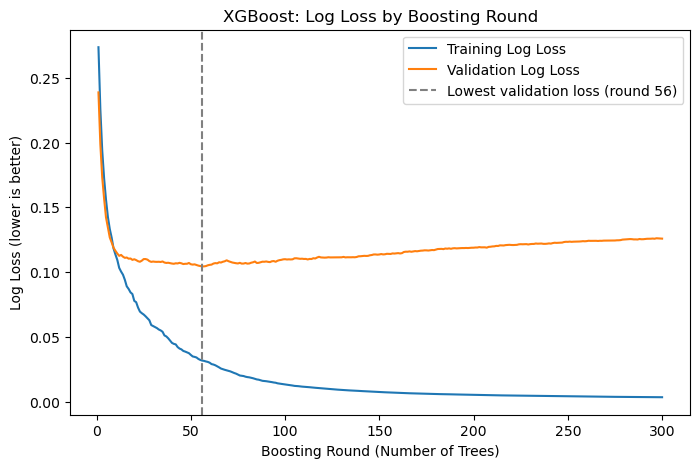

In [36]:
# Train XGBoost for 300 rounds without early stopping, recording log loss on both sets after each round
xg_curve = XGBClassifier(n_estimators = 300, eval_metric = 'logloss')
xg_curve.fit(X_tr, y_tr,
             eval_set = [(X_tr, y_tr), (X_val, y_val)],
             verbose = False)

# Find the round where validation log loss was lowest
results = xg_curve.evals_result()
best_round = np.argmin(results['validation_1']['logloss']) + 1

# Plot training vs. validation log loss for each boosting round
rounds = range(1, len(results['validation_0']['logloss']) + 1)
plt.figure(figsize=(8, 5))
plt.plot(rounds, results['validation_0']['logloss'], label='Training Log Loss')
plt.plot(rounds, results['validation_1']['logloss'], label='Validation Log Loss')
plt.axvline(best_round, linestyle='--', color='gray', label=f'Lowest validation loss (round {best_round})')
plt.title('XGBoost: Log Loss by Boosting Round')
plt.xlabel('Boosting Round (Number of Trees)')
plt.ylabel('Log Loss (lower is better)')
plt.legend()
plt.show()

---
### **Appendix: Choosing a Decision Threshold**

Every classifier we have used converts a predicted probability into a class label with a **threshold of 0.5**: `rf_model.predict(X_test)` is equivalent to `rf_model.predict_proba(X_test)[:, 1] >= 0.5`. In Week 9's appendix, we used **Youden's J** to choose a different threshold. Here, we apply it to the churn problem:

- **Youden's J:** The threshold at which TPR − FPR is largest.
- **Precision:** The proportion of predicted churners who actually churn.
- **Recall:** The proportion of actual churners the model identifies.

As in the rest of this notebook, we choose the threshold without using the test set (in Week 9, we used the test set only to demonstrate the method). `cross_val_predict` gives each training customer a churn probability from a forest that was not trained on that customer. We select the threshold from these probabilities and then evaluate it on the test set.

Lowering the threshold identifies more churners but also produces more false alarms. The right threshold depends on the cost of each error: if losing a customer costs more than a retention offer, a lower threshold is preferable. We will return to cost-based thresholds in Week 14.

Optimal Threshold (Youden's J): 0.35


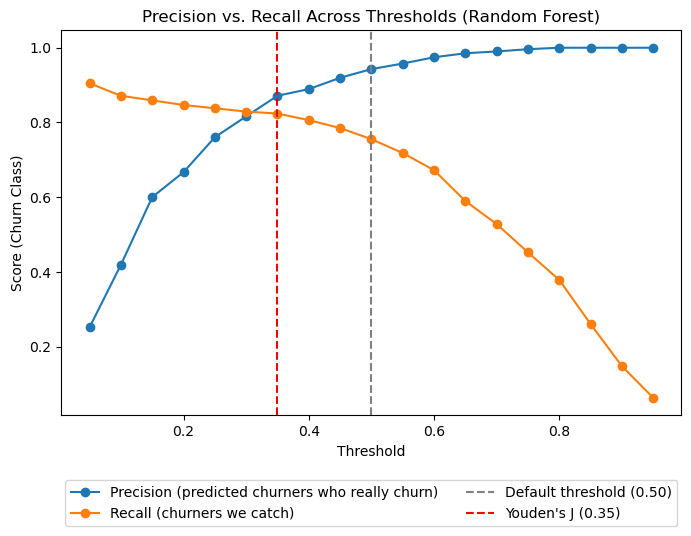

In [37]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, precision_score, recall_score

# Churn probabilities for every training customer, each one scored by a forest that didn't train on them
train_probs = cross_val_predict(RandomForestClassifier(random_state = 42), X_train, y_train,
                                cv = 5, method = 'predict_proba')[:, 1]

# Youden's J: the threshold where TPR - FPR is largest
fpr_cv, tpr_cv, thresholds_cv = roc_curve(y_train, train_probs)
j_stat = tpr_cv - fpr_cv
optimal_threshold_j = thresholds_cv[np.argmax(j_stat)]
print(f"Optimal Threshold (Youden's J): {optimal_threshold_j:.2f}")

# Precision and recall at thresholds from 0.05 to 0.95
thresholds = np.arange(0.05, 0.96, 0.05)
precisions = []
recalls = []
for t in thresholds:
    preds = (train_probs >= t).astype(int)
    precisions.append(precision_score(y_train, preds, zero_division = 0))
    recalls.append(recall_score(y_train, preds))

# Plot the trade-off
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions, marker='o', label='Precision (predicted churners who really churn)')
plt.plot(thresholds, recalls, marker='o', label='Recall (churners we catch)')
plt.axvline(0.5, linestyle='--', color='gray', label='Default threshold (0.50)')
plt.axvline(optimal_threshold_j, linestyle='--', color='red', label=f"Youden's J ({optimal_threshold_j:.2f})")
plt.title('Precision vs. Recall Across Thresholds (Random Forest)')
plt.xlabel('Threshold')
plt.ylabel('Score (Churn Class)')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2) # Legend below the plot so it doesn't cover the lines
plt.show()

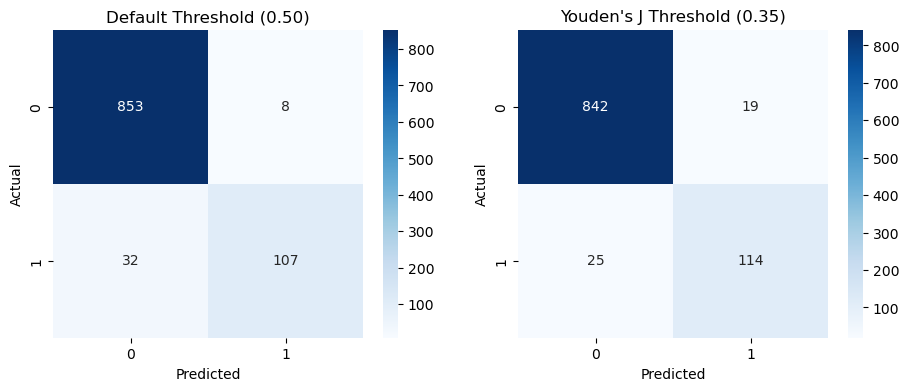

Default (0.50): caught 107 of 139 churners | 8 false alarms | F1 = 0.84
Youden's J (0.35): caught 114 of 139 churners | 19 false alarms | F1 = 0.84


In [38]:
from sklearn.metrics import confusion_matrix

# Churn probabilities for the test customers from our trained forest
test_probs = rf_model.predict_proba(X_test)[:, 1]

# Everything above the threshold becomes 1 (churn), else 0
default_preds = (test_probs >= 0.5).astype(int) # Same as rf_model.predict(X_test)
custom_preds = (test_probs >= optimal_threshold_j).astype(int)

# Compare the two confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(confusion_matrix(y_test, default_preds), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Default Threshold (0.50)')
sns.heatmap(confusion_matrix(y_test, custom_preds), annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title(f"Youden's J Threshold ({optimal_threshold_j:.2f})")
for ax in axes:
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.show()

# Summarize what changed
for name, preds in [("Default (0.50)", default_preds), (f"Youden's J ({optimal_threshold_j:.2f})", custom_preds)]:
    cm = confusion_matrix(y_test, preds)
    print(f"{name}: caught {cm[1, 1]} of {cm[1].sum()} churners | {cm[0, 1]} false alarms | F1 = {f1_score(y_test, preds):.2f}")